In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [2]:
from pathlib import Path

# Locate the dataset
dataset_path = Path.cwd().parent / "Datasets" / "churn-bigml-80.csv"

# Load the dataset
df = pd.read_csv(dataset_path)

# Display first five rows
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check target distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (2666, 20)

Column names:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes    

In [4]:
# Separate input features and target variable

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2666, 19)
Target shape: (2666,)


In [5]:
# Identify numerical and categorical columns
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumerical columns:", numerical_columns)

Categorical columns: ['State', 'International plan', 'Voice mail plan']

Numerical columns: ['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


C:\Users\hp\AppData\Local\Temp\ipykernel_2656\939851051.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()


In [6]:
# Identify numerical and categorical columns
categorical_columns = X.select_dtypes(include=["str"]).columns.tolist()
numerical_columns = X.select_dtypes(exclude=["str"]).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumerical columns:", numerical_columns)

Categorical columns: ['State', 'International plan', 'Voice mail plan']

Numerical columns: ['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


In [7]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2132, 19)
Testing data: (534, 19)


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [9]:
# Create a preprocessor for numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (2132, 71)
Processed testing data: (534, 71)


In [10]:
# Create and train the Logistic Regression model
model = LogisticRegression(max_iter=1000)

model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [11]:
# Predict customer churn
y_pred = model.predict(X_test_processed)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[False, False, False, False, False, False, False, False, False, False]

First 10 predicted values:
[False False False False False False False False False False]


In [12]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Model Evaluation:")
print("-----------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

Model Evaluation:
-----------------
Accuracy: 0.8426966292134831
Precision: 0.425
Recall: 0.21794871794871795


In [13]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[433  23]
 [ 61  17]]


In [14]:
# Generate classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.88      0.95      0.91       456
        True       0.42      0.22      0.29        78

    accuracy                           0.84       534
   macro avg       0.65      0.58      0.60       534
weighted avg       0.81      0.84      0.82       534



In [15]:
# Calculate predicted probabilities
y_prob = model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc_score)

AUC Score: 0.7435335132703553


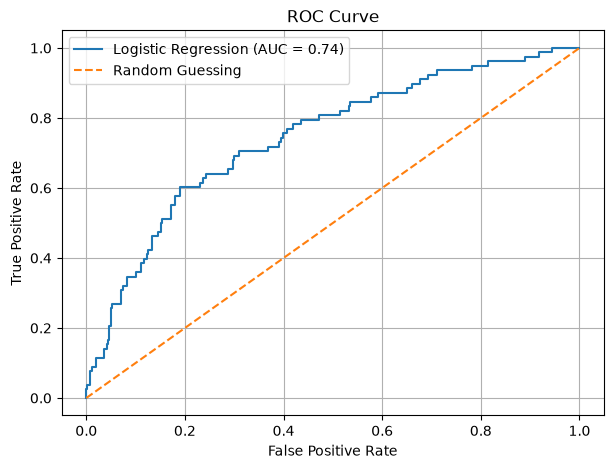

In [16]:
# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [17]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract model coefficients
coefficients = model.coef_[0]

# Calculate odds ratios
odds_ratios = np.exp(coefficients)

# Create a table
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds Ratio": odds_ratios
})

# Display the most influential features
coefficient_df["Absolute Coefficient"] = abs(coefficient_df["Coefficient"])

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

coefficient_df.head(10)

,Feature,Coefficient,Odds Ratio,Absolute Coefficient
59,cat__State_TX,1.374867,3.954551,1.374867
67,cat__International plan_No,-1.220119,0.295195,1.220119
68,cat__International plan_Yes,1.193096,3.297273,1.193096
55,cat__State_RI,-1.031469,0.356483,1.031469
42,cat__State_MT,0.963425,2.620657,0.963425
61,cat__State_VA,-0.919696,0.398640,0.919696
38,cat__State_MI,0.803919,2.234279,0.803919
15,num__Customer service calls,0.795884,2.216401,0.795884
47,cat__State_NJ,0.790253,2.203955,0.790253
27,cat__State_HI,-0.788845,0.454369,0.788845


In [18]:
# Final model summary
print("LOGISTIC REGRESSION - FINAL SUMMARY")
print("-----------------------------------")
print("Dataset size:", df.shape)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features after encoding:", X_train_processed.shape[1])
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("AUC Score:", round(auc_score, 4))

LOGISTIC REGRESSION - FINAL SUMMARY
-----------------------------------
Dataset size: (2666, 20)
Training samples: 2132
Testing samples: 534
Number of features after encoding: 71
Accuracy: 0.8427
Precision: 0.425
Recall: 0.2179
AUC Score: 0.7435


## Conclusion

In this task, we implemented Logistic Regression to predict customer churn using a telecom customer dataset.

The following steps were performed:

1. **Data Loading:** Loaded the customer churn dataset using Pandas.
2. **Data Exploration:** Examined the dataset, its features, data types, and missing values.
3. **Feature Selection:** Separated input features (X) and target variable (Churn).
4. **Data Splitting:** Divided the dataset into 80% training data and 20% testing data.
5. **Data Preprocessing:**
   - Applied StandardScaler to numerical features.
   - Applied OneHotEncoder to categorical features.
6. **Model Training:** Trained a Logistic Regression model using Scikit-learn.
7. **Prediction:** Predicted whether customers would leave or stay.
8. **Model Evaluation:** Evaluated performance using accuracy, precision, recall, confusion matrix, F1-score, ROC curve, and AUC score.
9. **Coefficient Interpretation:** Examined model coefficients and odds ratios to understand how different features influence customer churn.

**Result:** Successfully implemented a Logistic Regression classification model and evaluated its ability to predict customer churn.